# 5B. Transfer Learning - Intel Image (MobileNetV2)

In [1]:
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

In [2]:
BASE = "../datasets/Object Detection/Intel Image Classification"
train = keras.utils.image_dataset_from_directory(
    BASE, image_size=(128, 128), validation_split=0.2, subset="training", seed=42)
val = keras.utils.image_dataset_from_directory(
    BASE, image_size=(128, 128), validation_split=0.2, subset="validation", seed=42)

n_classes = len(train.class_names)
print("classes:", train.class_names)

train = train.prefetch(2)
val = val.prefetch(2)

Found 12632 files belonging to 6 classes.


Using 10106 files for training.


Found 12632 files belonging to 6 classes.


Using 2526 files for validation.


classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [3]:
base = keras.applications.MobileNetV2(include_top=False, input_shape=(128, 128, 3))
base.trainable = False

model = keras.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Rescaling(1./127.5, offset=-1),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dense(n_classes, activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,340,358 (8.93 MB)

 Trainable params: 82,374 (321.77 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [4]:
history = model.fit(train, validation_data=val, epochs=3)

Epoch 1/3
316/316 ━━━━━━━━━━━━━━━━━━━━ 30s 89ms/step - accuracy: 0.8862 - loss: 0.3126 - val_accuracy: 0.9121 - val_loss: 0.2465
Epoch 2/3
316/316 ━━━━━━━━━━━━━━━━━━━━ 28s 89ms/step - accuracy: 0.9287 - loss: 0.1979 - val_accuracy: 0.9153 - val_loss: 0.2350
Epoch 3/3
316/316 ━━━━━━━━━━━━━━━━━━━━ 139s 442ms/step - accuracy: 0.9437 - loss: 0.1499 - val_accuracy: 0.9137 - val_loss: 0.2507


In [5]:
loss, acc = model.evaluate(val)
print(f"val acc: {acc:.4f}")

 1/79 ━━━━━━━━━━━━━━━━━━━━ 5s 70ms/step - accuracy: 0.8438 - loss: 0.3226

 2/79 ━━━━━━━━━━━━━━━━━━━━ 5s 76ms/step - accuracy: 0.9219 - loss: 0.1826

 3/79 ━━━━━━━━━━━━━━━━━━━━ 5s 74ms/step - accuracy: 0.9375 - loss: 0.1862

 4/79 ━━━━━━━━━━━━━━━━━━━━ 5s 71ms/step - accuracy: 0.9219 - loss: 0.2291

 5/79 ━━━━━━━━━━━━━━━━━━━━ 5s 70ms/step - accuracy: 0.9187 - loss: 0.2457

 6/79 ━━━━━━━━━━━━━━━━━━━━ 5s 71ms/step - accuracy: 0.9062 - loss: 0.2560

... (71 outputs left out)

78/79 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.9135 - loss: 0.2510

79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.9137 - loss: 0.2507

79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 70ms/step - accuracy: 0.9137 - loss: 0.2507


val acc: 0.9137


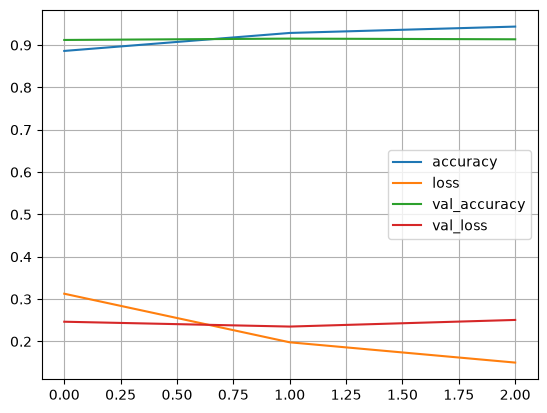

In [6]:
for k, v in history.history.items():
    plt.plot(v, label=k)
plt.legend()
plt.grid()
plt.show()